## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [26]:
# Your Phase 1 solution to the problem goes here.


In [27]:
#1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

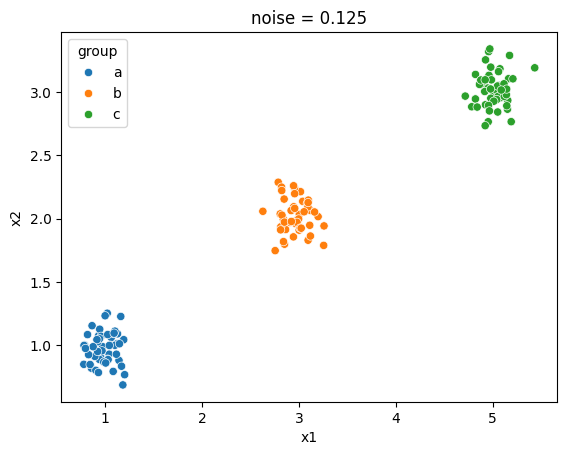

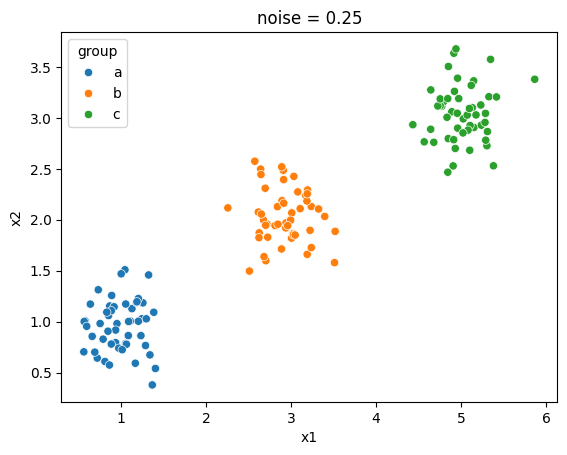

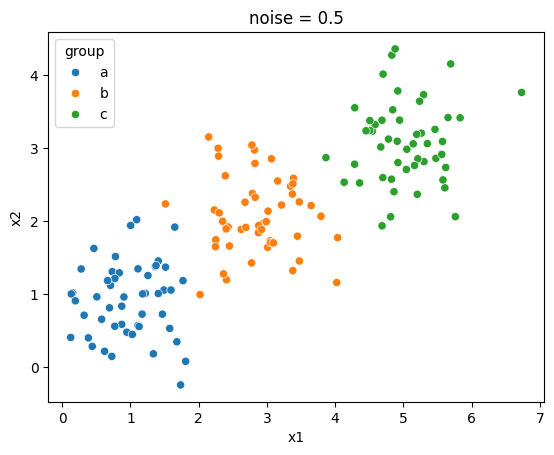

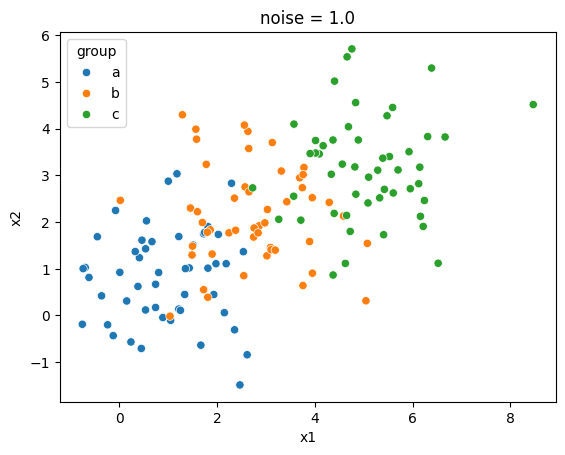

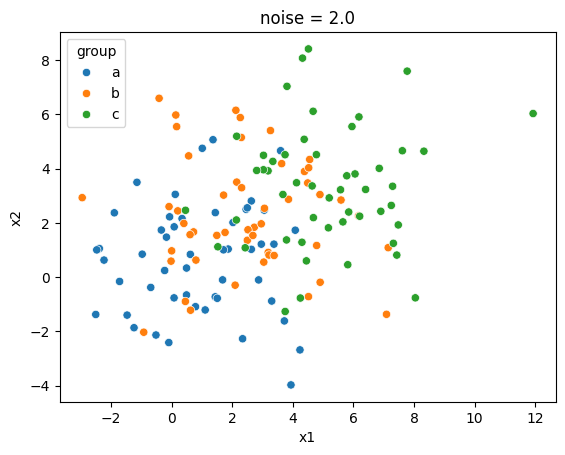

In [28]:
#2
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group").set(title="noise = 0.125")
plt.show()    #0.125

sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group").set(title="noise = 0.25")
plt.show()    #0.25

sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group").set(title="noise = 0.5")
plt.show()    #0.5

sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group").set(title="noise = 1.0")
plt.show()    #1.0

sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group").set(title="noise = 2.0")
plt.show()    #2.0

#As noise increases, the colors get less visually distinctive. When the noise in 0.125,
#the clusters are tight and distinctive, but at noise = 2.0 they are scattered all over.

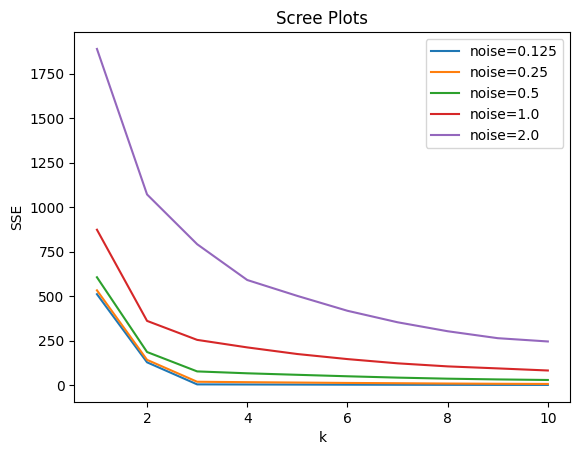

In [29]:
#3
from sklearn.cluster import KMeans
ks = np.arange(1, 11)

X = df0_125[["x1", "x2"]]
SSE0_125 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

X = df0_25[["x1", "x2"]]
SSE0_25 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

X = df0_5[["x1", "x2"]]
SSE0_5 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

X = df1_0[["x1", "x2"]]
SSE1_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

X = df2_0[["x1", "x2"]]
SSE2_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE0_125, label="noise=0.125")
sns.lineplot(x=ks, y=SSE0_25, label="noise=0.25")
sns.lineplot(x=ks, y=SSE0_5, label="noise=0.5")
sns.lineplot(x=ks, y=SSE1_0, label="noise=1.0")
sns.lineplot(x=ks, y=SSE2_0, label="noise=2.0")

plt.title("Scree Plots")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

#As noise increases, SSE is higher at every k.
#At lower noise there is a clear "elbow" at k=3.
#There is basically no clear 'elbow' at noise=2.0 as it fades gradually.
#Therefore, with low noise you can pick k=3 for certain, but you cannot with hih noise.

In [30]:
#4
#SSE always decreases as k increases, so can't just choose the k with the lowest SSE.
#Instead, look for the k where adding another cluster stops helping very much.
#Here, there are 3 true groups, so SSE drops a lot up to k=3, but not much after.
#The "elbow" is at k=3. There is virtually no "elbow" at the higher groups because they overlap.

In [ ]:
#Q2
from google.colab import files
uploaded = files.upload()

In [ ]:
#1
df = pd.read_csv("SIPRI Military Expenditure Database.csv")
df = df.loc[df["Year"] == 2020]
df = df.dropna()  #drops empty columns
df.info()
#pretty sure no more cleaning is required here

In [ ]:
#2
# scaling data
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [ ]:
model = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model.fit(X)
df["cluster"] = model.predict(X)
# scater plot
sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster")
plt.show()
# groupby
df.groupby("cluster")[features].describe()

# The scree plot's elbow is around k=3, so I used 3 clusters.
# Cluster 2 is only the United States, with the highest total spending(by far) and very
# high spending per capita. Cluster 0 is 21 countries with high spending per
# capita but moderate total spending. The one outlier there is probably a very small, but wealthy country.
# Cluster 1 is the other 126 countries, with low spending per capita and low total spending. The clusters are mostly separated by spending
# per capita, and the US is an outlier in the whole data set because its total spending is so much larger than everyone else's.

In [ ]:
#3
# scale
features3 = ["Percent of Government Spending", "Percent of GDP"]
unscaled3 = df.loc[:, features3]
mins3 = unscaled3.min()
ranges3 = unscaled3.max() - mins3
X3 = (unscaled3 - mins3) / ranges3

# scree plot
ks = np.arange(1, 11)
SSE_3 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE_3).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [ ]:
model3 = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model3.fit(X3)
df["cluster3"] = model3.predict(X3)
# scatter plot
sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster3")
plt.show()
# groupby
df.groupby("cluster3")[features3].describe()

In [ ]:
# 3
# The scree plot bends around k=2 to 3, so I used 3 clusters.
# Cluster 2 is 99 countries that spend a low share of their budget and GDP on the military.
# Cluster 0 is 39 countries in the middle, and cluster 1 is 10 countries with the highest shares.
# The US is not an outlier here unlike Q2. Countries are grouped by what pecent
# of their budget and economy goes to the military, versus by how much they spend in total.
# Therefore, the clusters are low, medium, and high levels along one trend instead of one big outlier.

In [ ]:
# 4
# scale
features4 = ["Spending (2020 USD)", "Spending per Capita",
             "Percent of Government Spending", "Percent of GDP"]
unscaled4 = df.loc[:, features4]
mins4 = unscaled4.min()
ranges4 = unscaled4.max() - mins4
X4 = (unscaled4 - mins4) / ranges4

# Scree plot
ks = np.arange(1, 11)
SSE4 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X4).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE4).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [ ]:
model4 = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model4.fit(X4)
df["cluster4"] = model4.predict(X4)

df.groupby("cluster4")[features4].describe()

In [ ]:
df.loc[df["Country"] == "United States of America", ["Country", "cluster4"]]
#4
# The Scree plot only has a small bend around k=3, so the elbow is not as clear as it was previously.
# The US is in cluster 2 with 5 other countries that are high on spending, spending per capita, and percent of GDP.
# In part 2 the US was alone, so here it is grouped with other countries that spend a lot per person and share of GDP.

In [ ]:
# 5
# Yes. It showed that the US is an outlier in total spending (part 2) and that countries
# fall into low, medium and high spending (part 3). But there are a few limits:
# k is not always clear and one outlier can take over a cluster.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]